### Data Preparation

In [1]:
import tensorflow as tf
import functools
import numpy as np
import os
import json
import torch
import torch_geometric as pyg

d:\Dyplom\gcn\Lib\site-packages\torch_geometric\typing.py:68: UserWarning: An issue occurred while importing 'pyg-lib'. Disabling its usage. Stacktrace: [WinError 127] The specified procedure could not be found
  warnings.warn(f"An issue occurred while importing 'pyg-lib'. "
d:\Dyplom\gcn\Lib\site-packages\torch_geometric\typing.py:124: UserWarning: An issue occurred while importing 'torch-sparse'. Disabling its usage. Stacktrace: [WinError 127] The specified procedure could not be found
  warnings.warn(f"An issue occurred while importing 'torch-sparse'. "


In [2]:
import torch_cluster

In [3]:
def generate_noise(position_seq, noise_std):
    velocity_seq = position_seq[:, 1:, :] - position_seq[:, :-1, :]
    time_steps = velocity_seq.size(1)
    velocity_noise = torch.randn_like(velocity_seq) * (noise_std / time_steps ** 0.5)
    velocity_noise = velocity_noise.cumsum(dim=1)
    pos_noise = velocity_noise.cumsum(dim=1)
    pos_noise = torch.cat((torch.zeros_like(pos_noise)[:,0:1], pos_noise), dim = 1)
    return pos_noise

In [4]:
def preprocess(node_features, pos_seq, target_pos, acc_mean, acc_std, noise_std):
    #apply noise
    pos_noise = generate_noise(pos_seq, noise_std)
    pos_seq = pos_seq + pos_noise

    #calculcate velocities
    current_pos = pos_seq[:, -1, :]
    vel_seq = pos_seq[:, 1:, :] - pos_seq[:, :-1, :]

    #construct the graph based on the distances between particles
    n_particle = current_pos.size(0)
    edge_index = pyg.nn.radius_graph(current_pos, 1000, loop=True, max_num_neighbors = n_particle)

    dim = current_pos.size(-1)
    edge_displacement = (torch.gather(current_pos, dim = 0, index=edge_index[0].unsqueeze(-1).expand(-1, dim)) - torch.gather(current_pos, dim = 0, index=edge_index[1].unsqueeze(-1).expand(-1, dim)))
    edge_displacement /= 1000
    edge_distance = torch.norm(edge_displacement, dim=-1, keepdim=True)

    #add bounderies handling in case of water
    
    if target_pos is not None:
        prev_velocity = vel_seq[:, -1, :]
        next_velocity = target_pos + pos_noise[:, -1, :] - current_pos
        acceleration = next_velocity - prev_velocity
        acceleration = (acceleration - acc_mean) / torch.sqrt(acc_std ** 2 + noise_std ** 2) 
    else:
        acceleration = None
    
    graph = pyg.data.Data(
        x = node_features,
        edge_index = edge_index,
        edge_attr = torch.cat((edge_displacement, edge_distance), dim = -1),
        y = acceleration,
        pos = vel_seq.reshape(vel_seq.size(0), -1)
    )
    return graph

In [5]:
def calculate_main_statistics(positions: np.ndarray) -> torch.Tensor:
    velocities = positions[:, 1:] - positions[:, :-1]
    accelerations = velocities[:, 1:] - velocities[:, :-1]
    acc_mean = torch.tensor(np.mean(accelerations, axis = (0,1)))
    acc_std = torch.tensor(np.std(accelerations, axis = (0,1)))
    return acc_mean, acc_std

In [6]:
class OneStepDS(pyg.data.Dataset):
    def __init__(self, data_path, file_path, window_length = 7, noise_std = 0.0, return_pos = False):
        super().__init__()
        with open(os.path.join(data_path, file_path)) as f:
            particles = json.load(f)

        arrays = []
        masses = []
        for entry in particles['entries']:
            arrays.append(np.array(entry['positions']))
            masses.append(int(entry['mass']))
        self.positions = np.array(arrays)


        self.window_length = window_length
        self.noise_std = noise_std
        self.return_pos = return_pos

        self.particle_idx = np.array(masses, dtype=np.int64)
        self.windows = []
        self.acc_mean, self.acc_std = calculate_main_statistics(self.positions)
        windows_count = self.positions.shape[1] // self.window_length
        for i in range(0, windows_count):
            particles = self.particle_idx
            positions = self.positions[ :, i * window_length: i * window_length + window_length, :]
            self.windows.append({'particles' : particles ,'position' : positions})

    def get_main_statistics(self):
        return self.acc_mean, self.acc_std
    
    def len(self):
        return len(self.windows)

    def get(self, index):
        window = self.windows[index]
        pos_seq = window['position'][ :, :- 1, :]
        target_pos  = window['position'][ :, -1, :]
        particles = window['particles']
        pos_seq = torch.from_numpy(pos_seq)
        target_pos = torch.from_numpy(target_pos)
        particles = torch.from_numpy(particles)
        with torch.no_grad():
            graph = preprocess(particles, pos_seq, target_pos,self.acc_mean, self.acc_std, self.noise_std)
        if self.return_pos:
            return graph, pos_seq
        return graph        
    



In [7]:
class RolloutDS(pyg.data.Dataset):
    def __init__(self, data_path, file_path, noise_std = 0.0, return_pos = False):
        super().__init__()
        with open(os.path.join(data_path, file_path)) as f:
            particles = json.load(f)

        arrays = []
        masses = []
        for entry in particles['entries']:
            masses.append(int(entry['mass']))
            arrays.append(np.array(entry['positions']))
        self.positions = np.array(arrays)
        self.particle_type = np.array(masses)

    def len(self):
        return len(self.positions)
    
    def get(self):
        pos_seq = self.positions
        particle_type = self.particle_type
        pos_seq = torch.from_numpy(pos_seq)
        return {"particle_type": particle_type, "position": pos_seq}

torch.Size([100, 6, 3])
The first item in the valid set is a graph: Data(x=[100], edge_index=[2, 10000], edge_attr=[10000, 4], y=[100, 3], pos=[100, 15])
This graph has 100 nodes and 10000 edges.
Each node is a particle and each edge is the interaction between two particles.
Each node has 1 categorial feature (Data.x), which represents the type of the node.
Each node has a 15-dim feature vector (Data.pos), which represents the positions and velocities of the particle (node) in several frames.
Each edge has a 4-dim feature vector (Data.edge_attr), which represents the relative distance and displacement between particles.
The model is expected to predict a 3-dim vector for each node (Data.y), which represents the acceleration of the particle.
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64

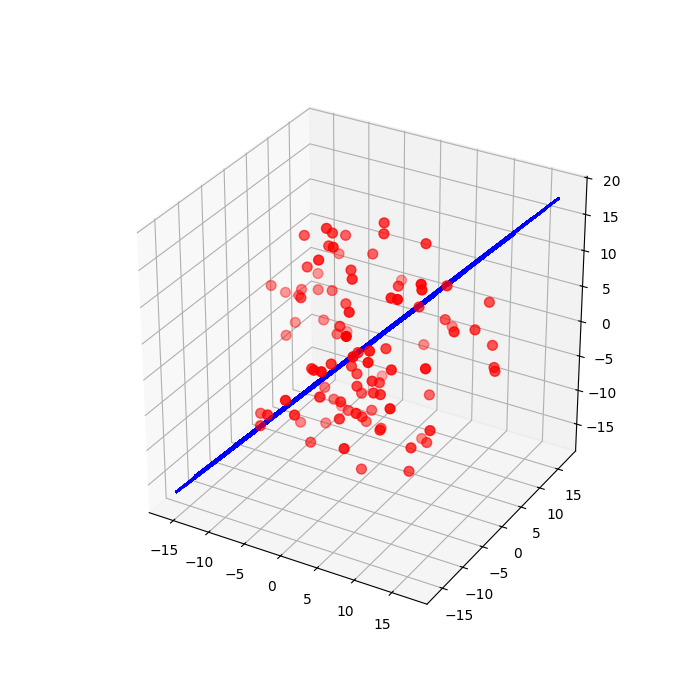

In [22]:
%matplotlib widget
import matplotlib.pyplot as plt
import networkx as nx

ds_sample = OneStepDS('', 'validation_ds.json', return_pos=True)
graph, pos = ds_sample.get(20)
print(pos.shape)
print(f"The first item in the valid set is a graph: {graph}")
print(f"This graph has {graph.num_nodes} nodes and {graph.num_edges} edges.")
print(f"Each node is a particle and each edge is the interaction between two particles.")
print(f"Each node has {graph.num_node_features} categorial feature (Data.x), which represents the type of the node.")
print(f"Each node has a {graph.pos.size(1)}-dim feature vector (Data.pos), which represents the positions and velocities of the particle (node) in several frames.")
print(f"Each edge has a {graph.num_edge_features}-dim feature vector (Data.edge_attr), which represents the relative distance and displacement between particles.")
print(f"The model is expected to predict a {graph.y.size(1)}-dim vector for each node (Data.y), which represents the acceleration of the particle.")

nx_graph = pyg.utils.to_networkx(graph).to_undirected()
print(nx_graph.nodes())
x = [pos[i][0][0] for i in nx_graph.nodes()]
y = [pos[i][0][1] for i in nx_graph.nodes()]
z = [pos[i][0][2] for i in nx_graph.nodes()]
fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(x, y, z, c='r', s=50)
for edge in nx_graph.edges():
    x_vals = [pos[edge[0]][0], pos[edge[1]][0]]
    y_vals = [pos[edge[0]][1], pos[edge[1]][1]]
    z_vals = [pos[edge[0]][2], pos[edge[1]][2]]
    ax.plot(x_vals, y_vals, z_vals, c='b')
ax.set_box_aspect([1,1,1])  # equal aspect
plt.ion()
plt.show()

In [9]:
import math
import os
import torch
import torch_geometric as pyg
import torch_scatter

In [ ]:
class MLP(torch.nn.Module):
    def __init__(self, input_size, hidden_size, output_size, layers, layer_norm=True):
        super().__init__()
        self.layers = torch.nn.ModuleList()
        self.layers.append(torch.nn.Linear(input_size, hidden_size))
        self.layers.append(torch.nn.ReLU())
        for layer in range(layers - 2):
            self.layers.append(torch.nn.Linear(hidden_size, hidden_size))
            if layer != layers - 3:
                self.layers.append(torch.nn.ReLU())
        self.layers.append(torch.nn.Linear(hidden_size, output_size))
        if layer_norm:
            self.layers.append(torch.nn.LayerNorm(output_size))
        self.reset_parameters()

    def reset_parameters(self):
        for layer in self.layers:
            if isinstance(layer, torch.nn.Linear):
                layer.weight.data.normal_(0, 1 / math.sqrt(layer.in_features))
                layer.bias.data.fill_(0)
    
    def forward(self, input_data):
        for layer in self.layers:
            input_data = layer(input_data)
        return input_data 

In [11]:
class InteractionNetwork(pyg.nn.MessagePassing):
    def __init__(self, hidden_size, layers):
        super().__init__()
        self.lin_edge = MLP(hidden_size * 3, hidden_size, hidden_size, layers)
        self.lin_node = MLP(hidden_size * 2, hidden_size, hidden_size, layers)
    
    def forward(self, x, edge_index, edge_feature):
        edge_out, aggr = self.propagate(edge_index, x = (x, x), edge_feature = edge_feature)
        node_out = self.lin_node(torch.cat((x, aggr), dim = -1))
        edge_out = edge_feature + edge_out
        node_out = x + node_out
        return node_out, edge_out
    
    def message(self, x_i, x_j, edge_feature):
        x = torch.cat((x_i, x_j, edge_feature), dim= -1)
        x = self.lin_edge(x)
        return x

    def aggregate(self, inputs, index, dim_size = None):
        out = torch_scatter.scatter(inputs, index, dim = self.node_dim, dim_size=dim_size, reduce='sum')
        return (inputs, out)

In [12]:
class LearningSimulator(torch.nn.Module):
    def __init__(self, hidden_size, gnn_layers, particle_types_dim, dim, window_size):
        super().__init__()
        self.window_size = window_size
        self.embed_type = torch.nn.Embedding(5, particle_types_dim)
        self.node_in = MLP(particle_types_dim + dim * window_size, hidden_size, hidden_size, 3)
        self.edge_in = MLP(dim + 1, hidden_size, hidden_size, 3)
        self.node_out = MLP(hidden_size, hidden_size, dim, 3, layer_norm=False)
        self.gnn_layers = gnn_layers
        self.layers = torch.nn.ModuleList([InteractionNetwork(hidden_size, 3) for _ in range(gnn_layers)])
        self.reset_params()
        
    def reset_params(self):
        torch.nn.init.xavier_uniform_(self.embed_type.weight)

    def forward(self, data):
        embed_tensor =self.embed_type(data.x)
        node_feature = torch.cat((embed_tensor, data.pos), dim = -1).to(torch.float32)
        node_feature = self.node_in(node_feature)
        edge_feature = self.edge_in(data.edge_attr.to(torch.float32))
        for i in range(self.gnn_layers):
            node_feature, edge_feature = self.layers[i](node_feature, data.edge_index, edge_feature=edge_feature)

        out = self.node_out(node_feature)
        return out


In [13]:
data_path= ''
model_path = os.path.join('model', 'final')
checkpoint_path = os.path.join('model', 'checkpoints')
rollout_path = os.path.join('rollout', 'NBody')

params = {
    'epoch': 5,
    "batch_size" : 1,
    "lr" : 1e-4,
    'noise' : 3e-4,
    'save_interval' : 1000,
    'eval_interval' : 1000,
    'rollout_interval' : 200000,
}

In [14]:
def rollout(model,particle_data, position_data, noise_std):
    device = next(model.parameters()).device
    model.eval()
    window_size = model.window_size + 1
    total_time = position_data.size(1)
    trajectory = position_data[:, :window_size, :]
    trajectory = trajectory.permute(1, 0, 2)
    particle_type = particle_data

    for time in (total_time - window_size):
        with torch.no_grad():
            graph = preprocess(particle_type, trajectory[:, -window_size, :], None)
            graph = graph.to(device)
            acc = model(graph).cpu()
            # add acceleration normalization

            current_pos = trajectory[:, -1, :]
            current_vel = current_pos - trajectory[:, -2, :]
            est_vel = current_vel + acc
            est_pos = current_pos + est_vel
            trajectory = torch.cat((trajectory, est_pos.unsqueeze(1)), dim=1)
    return trajectory

def oneStepMSE(simulator, ds, acc_std, noise):
    total_loss = 0
    total_mse = 0
    batch_count = 0
    simulator.eval()
    with torch.no_grad():
        scale = torch.sqrt(acc_std ** 2 + noise ** 2).cuda()
        for data in ds:
            data = data.cuda()
            pred = simulator(data)
            mse =  ((pred - data.y) * scale) ** 2
            mse = mse.sum(dim=-1).mean()
            loss = ((pred - data.y) ** 2).mean()
            total_mse = mse.item()
            total_loss += loss.item()
            batch_count += 1
    return total_loss / batch_count, total_mse / batch_count

def rolloutMSE(simulator, ds, noise):
    total_loss = 0.0
    batch_count = 0
    simulator.eval()
    for record in ds:
        rollout_data = rollout(simulator,  record.particle_type, record.position, noise)
        loss = (rollout_data - record["position"]) ** 2
        loss = loss.sum(dim=-1).mean()
        total_loss += loss.item()
        batch_count += 1
    return total_loss / batch_count

In [15]:
from tqdm import tqdm

def train(params, simulator, train_loader, valid_loader, valid_rollout_loader, acc_std):
    loss_fn = torch.nn.MSELoss()
    optimizer = torch.optim.Adam(simulator.parameters(), lr=params['lr'])
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma = 0.1 ** (1 / 5e6))

    train_loss_list = []
    eval_loss_list = []
    one_step_mse_list = []
    rollout_mse_list = []
    total_step = 0

    for i in range(params['epoch']):
        simulator.train()
        progress_bar = tqdm(train_loader, desc = f"Epoch: {i}")
        total_loss=0
        batch_count = 0
        for data in progress_bar:
            optimizer.zero_grad()
            data = data.cuda()
            pred = simulator(data)
            loss = loss_fn(pred, data.y.to(torch.float32))
            loss.backward()
            optimizer.step()
            scheduler.step()
            total_loss += loss.item()
            batch_count += 1
            progress_bar.set_postfix({"loss": loss.item(), "avg_loss": total_loss / batch_count, "lr": optimizer.param_groups[0]['lr']})
            total_step += 1
            train_loss_list.append((total_step, loss.item()))

            if total_step % params['eval_interval'] == 0:
                simulator.eval()
                eval_loss, one_step_mse = oneStepMSE(simulator, valid_loader, acc_std,  params['noise'])
                eval_loss_list.append((total_step, eval_loss))
                one_step_mse_list.append((total_step, one_step_mse))
                tqdm.write(f"\nEval loss: {eval_loss}, One step MSE: {one_step_mse}")
                simulator.train()
                
            if total_step % params['rollout_interval'] == 0:
                simulator.eval()
                rollout_mse = rollout_mse(simulator, valid_loader, params['noise'])
                rollout_mse_list.append((total_step, rollout_mse))
                tqdm.write(f"\nRollout MSE: {rollout_mse}")
                simulator.train()
            
            if total_step % params['save_interval'] == 0:
                torch.save({
                    "model": simulator.state_dict(),
                    "optimizer" : optimizer.state_dict(),
                    "scheulder" : scheduler.state_dict(),
                },
                os.path.join(checkpoint_path, f"checkout_{total_step}.pt"))
        torch.save({
            "model": simulator.state_dict(),
            "optimizer" : optimizer.state_dict(),
            "scheulder" : scheduler.state_dict(),
        },
        os.path.join(model_path, f"pretrained_model.pt"))
    return train_loss_list, eval_loss_list, one_step_mse_list, rollout_mse_list


In [16]:
train_ds = OneStepDS('', 'train_ds.json', window_length=7)
valid_ds = OneStepDS('', 'validation_ds.json')

train_loader = pyg.loader.DataLoader(train_ds, batch_size=params['batch_size'], shuffle=True, pin_memory = True, num_workers=0)
valid_loader = pyg.loader.DataLoader(valid_ds, batch_size=params['batch_size'], shuffle=False, pin_memory = True, num_workers =0)
valid_rollout_ds = RolloutDS('', 'train_ds.json',)

simulator = LearningSimulator(128, 10, 16, 3, 5)
simulator = simulator.cuda()

train_loss_list, eval_loss_list, onestep_mse_list, rollout_mse_list = train(params, simulator, train_loader, valid_loader, valid_rollout_ds, train_ds.acc_std)

Epoch: 0:  70%|███████   | 1003/1428 [00:23<01:08,  6.18it/s, loss=0.00756, avg_loss=0.0599, lr=0.0001]


Eval loss: 0.06553450649926977, One step MSE: 4.1619327206521716e-09


Epoch: 1:  40%|████      | 575/1428 [00:14<01:59,  7.13it/s, loss=0.00508, avg_loss=0.00757, lr=9.99e-5]


Eval loss: 0.03877435112436084, One step MSE: 2.6830953878896794e-09


Epoch: 2:  10%|█         | 146/1428 [00:05<02:53,  7.37it/s, loss=0.00531, avg_loss=0.0101, lr=9.99e-5]


Eval loss: 0.037614984863188594, One step MSE: 2.391074489735134e-09


... (5 outputs left out)


Eval loss: 0.03259465940883934, One step MSE: 2.175340103443817e-09


Epoch: 4:  90%|█████████ | 1291/1428 [00:31<00:20,  6.54it/s, loss=0.000917, avg_loss=0.00518, lr=9.97e-5]


Eval loss: 0.031683636897730474, One step MSE: 2.1552501452475765e-09


Epoch: 4: 100%|██████████| 1428/1428 [00:34<00:00, 41.42it/s, loss=0.00626, avg_loss=0.00596, lr=9.97e-5] 
